# 02. 탐색적 데이터 분석(EDA)과 시각화

**읽는 순서:** 자료 제공 범위 → 매출 분포 → 동일 상권의 시간 변화 → 야간·주말 비중 → 확인할 이상치.

01번 노트북을 먼저 실행하세요. 이 단계는 데이터의 특징을 파악하는 기술통계이며, 공연의 효과를 추정하지 않습니다. 모든 그래프는 `reports/figures/`에 PNG로도 저장합니다.

**기존 두 업종 기준선:** 이 노트북은 한식음식점·커피음료의 초기 분석 이력이다. 현재 외식업 10종 데이터셋·통계 분석은 08~10번, RDF·분석 도구는 06~07번을 사용한다. 최신 수집 자료의 연결·검증은 03~04번에서 수행한다.


In [1]:
from pathlib import Path
import json
import sys
import platform
import importlib.metadata
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# 프로젝트 루트 또는 notebooks 폴더에서 실행할 수 있습니다.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/raw/seoul_sales').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('졸업프로젝트 폴더 또는 notebooks 폴더에서 실행하세요.')
RAW = ROOT / 'data/raw'
ANALYSIS = ROOT / 'data/analysis'
REPORTS = ROOT / 'reports'
FIGURES = REPORTS / 'figures'
for folder in [ANALYSIS, REPORTS, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 16)
pd.set_option('display.max_rows', 16)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')
YEARS = [2023, 2024, 2025]
DISTRICTS = {'11110': '종로구', '11440': '마포구'}
INDUSTRIES = {'CS100001': '한식음식점', 'CS100010': '커피-음료'}
KEY = ['quarter', 'area_id', 'industry_id']
print('프로젝트:', ROOT)
print('Python:', platform.python_version())


프로젝트: C:\Coding\졸업프로젝트
Python: 3.12.14


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

DISTRICT_COLORS = {'종로구': '#36688d', '마포구': '#d46b32'}
font_names = {font.name for font in fm.fontManager.ttflist}
font = next((name for name in ['Malgun Gothic', 'NanumGothic', 'AppleGothic'] if name in font_names), 'DejaVu Sans')
sns.set_theme(style='whitegrid', font=font, rc={'axes.unicode_minus': False})
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160, 'font.size': 10})
path = ANALYSIS / 'sales_stores_panel.csv'
if not path.exists():
    raise FileNotFoundError('먼저 01_데이터_점검과_전처리.ipynb를 실행하세요.')
panel = pd.read_csv(path, dtype={'quarter': str, 'area_id': str, 'industry_id': str})
# 저장 후 다시 읽어도 키와 미제공 매출의 구분이 유지되는지 검사합니다.
assert not panel.duplicated(KEY).any()
assert panel.loc[panel['availability'].isin(['sales_absent', 'both_absent']), 'total_sales'].isna().all()

def save_figure(fig, filename):
    for ax in fig.axes:
        legend = ax.get_legend()
        if legend is not None and legend.get_title().get_text() == 'district':
            legend.set_title('지역')
    fig.tight_layout()
    fig.savefig(FIGURES / filename, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print('분석 패널:', len(panel), '행 / 상권:', panel['area_id'].nunique(), '개')


분석 패널: 3624 행 / 상권: 151 개


## 1. 어느 구간의 매출이 제공되는가?

셀의 값은 각 지역·업종·분기에서 매출 자료가 제공된 상권의 비율입니다. 비율이 낮은 구간은 매출 합계가 작아 보여도 경제활동 감소라고 바로 해석할 수 없습니다.


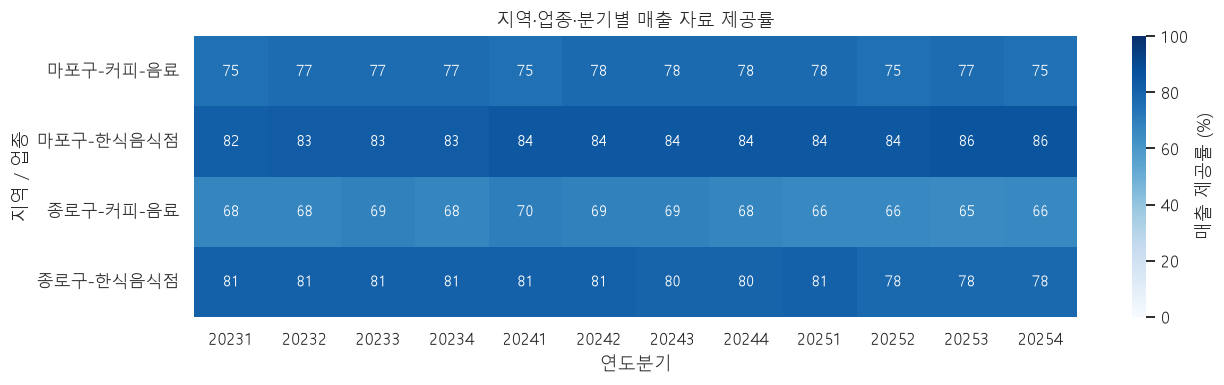

패널행  매출관측  상권수         매출중앙값_원  야간비중중앙값
district industry                                         
마포구      커피-음료     924   708   77 280,956,445.500    0.020
         한식음식점     924   777   77 942,808,968.000    0.174
종로구      커피-음료     888   600   74 261,325,245.500    0.013
         한식음식점     888   712   74 766,027,382.500    0.079

In [3]:
coverage = panel.groupby(['district', 'industry', 'quarter'], observed=True)['total_sales'].apply(lambda x: x.notna().mean() * 100)
coverage = coverage.unstack('quarter')
fig, ax = plt.subplots(figsize=(12, 3.6))
sns.heatmap(coverage, annot=True, fmt='.0f', vmin=0, vmax=100, cmap='Blues',
            cbar_kws={'label': '매출 제공률 (%)'}, ax=ax)
ax.set_title('지역·업종·분기별 매출 자료 제공률')
ax.set_xlabel('연도분기'); ax.set_ylabel('지역 / 업종')
save_figure(fig, '01_sales_coverage.png')
display(panel.groupby(['district', 'industry'], observed=True).agg(
    패널행=('area_id', 'size'), 매출관측=('total_sales', 'count'),
    상권수=('area_id', 'nunique'), 매출중앙값_원=('total_sales', 'median'),
    야간비중중앙값=('night_share', 'median')))


## 2. 매출 분포와 극단값

상권별 규모 차이가 크므로 양수 매출은 로그 축으로 봅니다. 0원·음수·미제공 행은 로그 그래프에 들어가지 않으며 개수를 별도로 표시합니다. 극단값은 오류라고 단정하지 않고 상권명과 점포 수를 함께 확인합니다.


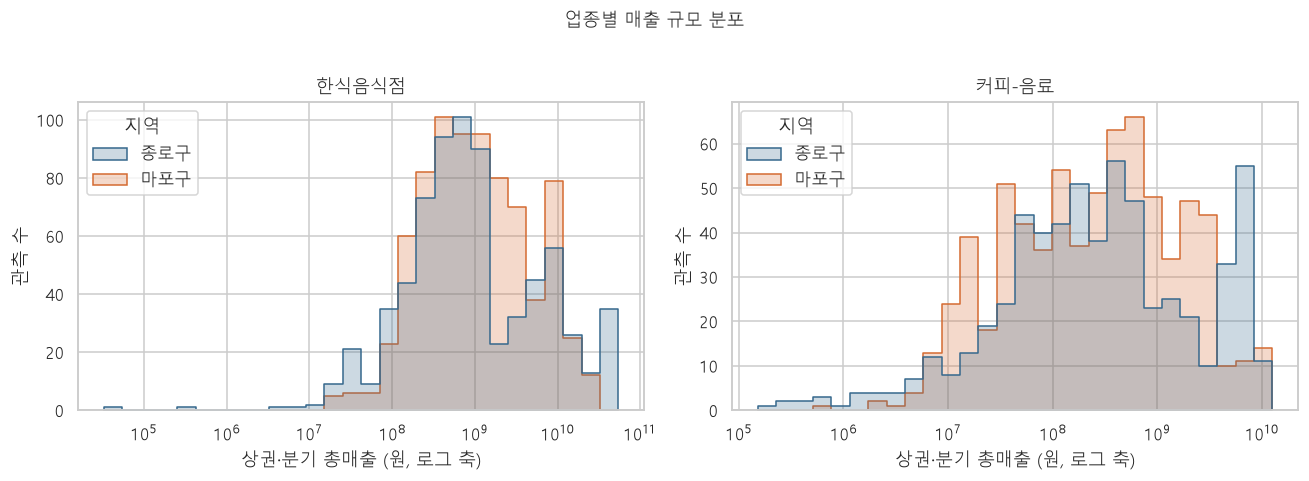

,그래프 제외 행
0원,0
음수,0
미제공/결측,827


,quarter,district,area_name,industry,total_sales,store_count,sales_per_store
820,20233,마포구,월드컵경기장역(월드컵경기장),한식음식점,"1,787,522,614.000",4.000,"446,880,653.500"
2028,20243,마포구,월드컵경기장역(월드컵경기장),한식음식점,"1,678,662,810.000",4.000,"419,665,702.500"
518,20232,마포구,월드컵경기장역(월드컵경기장),한식음식점,"1,669,554,138.000",4.000,"417,388,534.500"
1122,20234,마포구,월드컵경기장역(월드컵경기장),한식음식점,"1,669,225,520.000",4.000,"417,306,380.000"
3538,20254,마포구,월드컵경기장역(월드컵경기장),한식음식점,"1,657,896,587.000",4.000,"414,474,146.750"
2330,20244,마포구,월드컵경기장역(월드컵경기장),한식음식점,"1,566,247,344.000",4.000,"391,561,836.000"
216,20231,마포구,월드컵경기장역(월드컵경기장),한식음식점,"1,543,568,544.000",4.000,"385,892,136.000"
1726,20242,마포구,월드컵경기장역(월드컵경기장),한식음식점,"1,537,519,469.000",4.000,"384,379,867.250"
1424,20241,마포구,월드컵경기장역(월드컵경기장),한식음식점,"1,406,446,583.000",4.000,"351,611,645.750"
3236,20253,마포구,월드컵경기장역(월드컵경기장),한식음식점,"1,394,631,003.000",4.000,"348,657,750.750"


In [4]:
positive = panel.loc[panel['total_sales'].gt(0)].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, industry in zip(axes, INDUSTRIES.values()):
    sns.histplot(data=positive.loc[positive['industry'].eq(industry)], x='total_sales',
                 hue='district', palette=DISTRICT_COLORS, hue_order=list(DISTRICTS.values()), log_scale=True, bins=28, element='step', ax=ax)
    ax.set_title(industry); ax.set_xlabel('상권·분기 총매출 (원, 로그 축)'); ax.set_ylabel('관측 수')
fig.suptitle('업종별 매출 규모 분포', y=1.03)
save_figure(fig, '02_sales_distribution.png')
display(pd.Series({'0원': int(panel['total_sales'].eq(0).sum()),
                   '음수': int(panel['total_sales'].lt(0).sum()),
                   '미제공/결측': int(panel['total_sales'].isna().sum())}, name='그래프 제외 행').to_frame())
outliers = panel.nlargest(10, 'sales_per_store')[['quarter', 'district', 'area_name', 'industry',
                                               'total_sales', 'store_count', 'sales_per_store']]
display(outliers)
outliers.to_csv(REPORTS / 'sales_per_store_top10_review.csv', index=False, encoding='utf-8-sig')


## 3. 같은 상권을 계속 관측하면 매출이 어떻게 달라지는가?

12개 분기에 모두 유효한 매출이 있는 **상권×업종**만 선택합니다. 비교 도중 표본 구성이 달라지는 문제를 줄이기 위한 것입니다. 첫 분기를 100으로 놓은 명목 매출 지수이며 물가 변화를 제거하지 않았습니다.

이 균형 표본이 전체 상권을 대표한다는 뜻은 아닙니다. 선정된 상권 수를 함께 확인하세요.


균형 표본 상권 수
district industry            
마포구      커피-음료             54
         한식음식점             63
종로구      커피-음료             47
         한식음식점             58

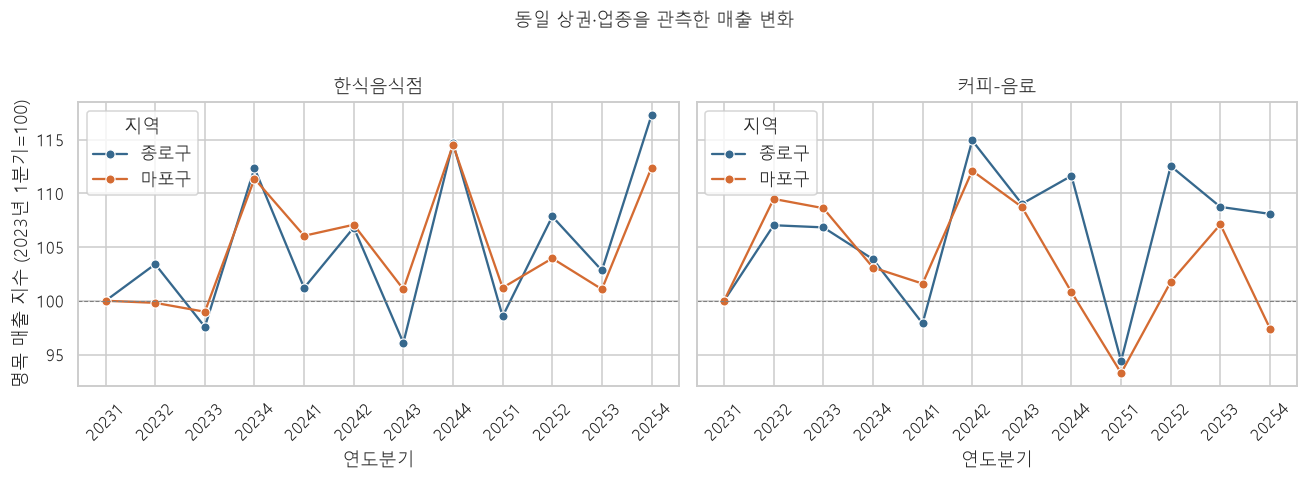

In [5]:
valid = panel['total_sales'].ge(0) & ~panel['negative_sales_flag']
valid_counts = panel.loc[valid].groupby(['area_id', 'industry_id'], observed=True)['quarter'].nunique()
balanced_keys = valid_counts.loc[valid_counts.eq(12)].reset_index()[['area_id', 'industry_id']]
balanced = panel.merge(balanced_keys, on=['area_id', 'industry_id'], how='inner', validate='many_to_one')
if balanced.empty:
    raise ValueError('12분기 균형 표본이 없습니다. 표본 기간을 재검토하세요.')
counts = balanced.groupby(['district', 'industry'], observed=True)['area_id'].nunique().rename('균형 표본 상권 수')
display(counts.to_frame())
trend = balanced.groupby(['district', 'industry', 'quarter'], observed=True)['total_sales'].sum(min_count=1).reset_index()
trend['sales_index'] = trend.groupby(['district', 'industry'], observed=True)['total_sales'].transform(lambda s: s / s.iloc[0] * 100 if s.iloc[0] > 0 else np.nan)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, industry in zip(axes, INDUSTRIES.values()):
    sns.lineplot(data=trend.loc[trend['industry'].eq(industry)], x='quarter', y='sales_index',
                 hue='district', palette=DISTRICT_COLORS, hue_order=list(DISTRICTS.values()), marker='o', ax=ax)
    ax.set_title(industry); ax.set_xlabel('연도분기'); ax.set_ylabel('명목 매출 지수 (2023년 1분기=100)')
    ax.tick_params(axis='x', rotation=45); ax.axhline(100, color='grey', lw=0.7, ls='--')
fig.suptitle('동일 상권·업종을 관측한 매출 변화', y=1.03)
save_figure(fig, '03_balanced_sales_trend.png')
trend.to_csv(REPORTS / 'balanced_sales_trend.csv', index=False, encoding='utf-8-sig')


## 4. 야간·주말 매출 비중

아래 상자 그림은 **상권별 비중의 분포**입니다. 큰 상권과 작은 상권에 같은 가중치를 줍니다. 그 아래 표는 같은 균형 표본에서 금액을 합한 뒤 나눈 **매출액 가중 비중**으로, 두 통계의 의미가 다릅니다.

21~24시 비중이 높다는 사실만으로 공연 관객의 소비라고 해석할 수는 없습니다.


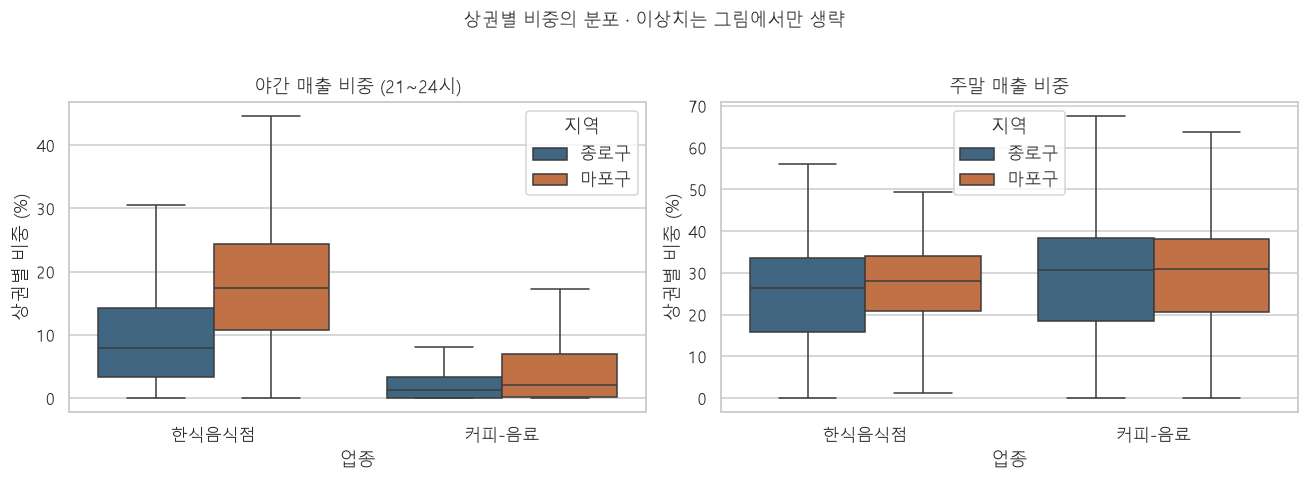

,district,industry,night_share_weighted_pct,weekend_share_weighted_pct
0,마포구,커피-음료,6.346,32.730
1,마포구,한식음식점,20.410,28.658
2,종로구,커피-음료,3.867,27.307
3,종로구,한식음식점,12.999,24.658


In [6]:
shares = panel.melt(id_vars=['district', 'industry', 'quarter'],
                    value_vars=['night_share', 'weekend_share'], var_name='metric', value_name='share')
shares['share_pct'] = shares['share'] * 100
labels = {'night_share': '야간 매출 비중 (21~24시)', 'weekend_share': '주말 매출 비중'}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, metric in zip(axes, labels):
    sns.boxplot(data=shares.loc[shares['metric'].eq(metric)], x='industry', y='share_pct',
                hue='district', palette=DISTRICT_COLORS, hue_order=list(DISTRICTS.values()), showfliers=False, ax=ax)
    ax.set_title(labels[metric]); ax.set_xlabel('업종'); ax.set_ylabel('상권별 비중 (%)')
fig.suptitle('상권별 비중의 분포 · 이상치는 그림에서만 생략', y=1.03)
save_figure(fig, '04_night_weekend_shares.png')
weighted_rows = []
for keys, group in balanced.groupby(['district', 'industry'], observed=True):
    record = {'district': keys[0], 'industry': keys[1]}
    for numerator, ratio in [('night_sales', 'night_share'), ('weekend_sales', 'weekend_share')]:
        usable = group.loc[group[ratio].notna()]
        denominator = usable['total_sales'].sum(min_count=1)
        record[ratio + '_weighted_pct'] = usable[numerator].sum(min_count=1) / denominator * 100 if denominator > 0 else np.nan
    weighted_rows.append(record)
weighted = pd.DataFrame(weighted_rows)
display(weighted)
weighted.to_csv(REPORTS / 'balanced_weighted_shares.csv', index=False, encoding='utf-8-sig')


## 5. 탐색 결과를 읽는 기준

- 제공률과 표본 수를 먼저 보고 매출 추이를 해석합니다.
- 총매출과 점포당 매출은 질문이 다릅니다. 점포 수가 0이거나 결측이면 점포당 매출을 계산하지 않습니다.
- 극단값·결측치·계절성을 확인한 뒤 공연 활동과의 관계를 분석합니다.
- 다음 노트북의 공연 수는 좌표를 확보한 시설에서 관측된 등록 공연 ID 수입니다. 실제 상연 횟수나 관객 수와 다릅니다.


In [7]:
summary = {
    'panel_rows': len(panel), 'sales_observed_rows': int(panel['total_sales'].notna().sum()),
    'sales_missing_rows': int(panel['total_sales'].isna().sum()),
    'balanced_area_industry_pairs': len(balanced_keys),
    'balanced_rows': len(balanced), 'figures_created': 4,
}
(REPORTS / 'eda_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
display(Markdown(f"**이번 자료의 관측 범위:** 총 {len(panel):,}행 중 매출 {summary['sales_observed_rows']:,}행 제공, "
                 f"{summary['sales_missing_rows']:,}행 결측. 12분기 균형 표본은 상권×업종 {len(balanced_keys):,}개입니다."))


**이번 자료의 관측 범위:** 총 3,624행 중 매출 2,797행 제공, 827행 결측. 12분기 균형 표본은 상권×업종 222개입니다.